*Text under CC-BY 4.0, code under BSD-3-Clause. (c) 2026 Francesco Mario Antonio Mitrotta.*

# Planning, Running and Checking the Abaqus Campaign of a Surrogate

[NB6](06_open_hole_tension.ipynb) built a deterministic model of the open-hole tension (OHT) plate, and on its coarsest mesh, M1, one run takes about five minutes. [NB8](08_polynomial_chaos_expansion.ipynb) showed that a direct sensitivity study of 15 uncertain inputs based on direct Monte Carlo with pick-freeze approach would take months (considering serial run execution), and it demonstrated the way out on a test function: a surrogate model via **polynomial chaos expansion** (PCE), fitted by point collocation from random runs and judged by its relative mean-square error $\varepsilon$ on held-out runs. Before such a surrogate can be fitted to the plate, it needs its Abaqus runs, and thousands of them. This notebook is about those runs: how many we need, how to make them affordable, how to run them, and how to check them before anything is fitted to them. [NB10](10_pce_surrogate_open_hole_tension.ipynb) then fits the surrogate, following the work by [Thapa et al. (2021)](https://doi.org/10.1007/s00158-020-02690-5). The employed model is our own (Hashin damage with energy softening, mesh M1, our parameters), from NB6, so the numbers from Thapa et al. are a scale for comparison and not a target.

## Learning goal

By the end of this notebook you will be able to:

- turn the number of terms of a PCE into a budget of Abaqus runs, and grow that budget in stages on one nested random
  design without wasting a run;
- measure how much we can gain from giving one job more cores and from running several jobs side by side, and
  estimate from that how long a campaign might take;
- run a large campaign of Abaqus jobs on a desktop or a server, and compare its real duration with the estimate;
- screen the results for runs that cannot be used, and tell whether the runs with much viscous energy look artificially strong and whether the rejected
  and flagged runs leave a hole in the input space.

First, the imports the whole notebook uses. Besides NumPy and Matplotlib, the standard library reads and writes the
design files (CSV) and the results (JSON), launches the Abaqus runs and counts categories (`Counter`). SciPy's
`curve_fit` makes the Amdahl fit of Part 2.

From `scripts/oht_campaign.py`, this notebook's campaign driver (Part 2, Step 1), come its test of whether a run can
be used, `acceptance_reason`, imported so that the notebook and the driver apply the same rule, the piece of that
test that finds the load drop, `drop_displacement` (Part 4, Step 3), and `drop_failed_frame`, which removes
the failed last frame of a job that stopped early (Part 4, Step 1). The cell also repeats NB8's `human_time`, which
writes a duration in hours, days or years.

In [1]:
# Standard library: reading and writing the design files (CSV) and the results (JSON), and counting.
import csv
import json
import math
from collections import Counter
# Standard library: launching the campaign driver (subprocess, sys) and file paths (pathlib).
import subprocess
import sys
from pathlib import Path

# NumPy for the arrays, Matplotlib for the figures.
import matplotlib.pyplot as plt
import numpy as np

# SciPy's curve fitting (the Amdahl fit of Part 2).
from scipy.optimize import curve_fit

# The campaign driver's test of whether a run can be used, its pieces, and the removal of a failed last frame (Part 4).
sys.path.insert(0, "../scripts")
from oht_campaign import acceptance_reason, drop_displacement, drop_failed_frame


def human_time(seconds):
    """Write a duration in the largest sensible unit.

    Parameters
    ----------
    seconds : float
        Duration [s].

    Returns
    -------
    str
        The duration in hours (below two days), days (below two years) or years.
    """
    # Below two days: hours.
    if seconds < 2 * 86400:
        return "%.0f h" % (seconds / 3600.0)
    # Below two years: days.
    if seconds < 2 * 365.25 * 86400:
        return "%.0f days" % (seconds / 86400.0)
    # Otherwise: years.
    return "%.0f years" % (seconds / (365.25 * 86400.0))

## Part 1 &ndash; How many Abaqus runs?

### Step 1 &ndash; The uncertain inputs and the outputs

Following [Thapa et al. (2021)](https://doi.org/10.1007/s00158-020-02690-5), every uncertain input is an independent Gaussian with a
coefficient of variation of 0.1 about its mean. They use 11 ply properties; we use 15, because our damage model (Hashin initiation, fracture-energy softening) has inputs theirs (Puck criterion, sudden stiffness drop) does not. The means are NB6's values, listed with their sources:

| Input | Meaning | Mean | Source |
|---|---|---|---|
| $E_1$, $E_2$ [MPa] | ply moduli, fibre and transverse | 172,400; 10,300 | Liu et al. (2010), Table 1, as in NB6 |
| $\nu_{12}$ [-] | in-plane Poisson ratio | 0.32 | same |
| $G_{12}$ [MPa] | in-plane shear modulus; $G_{13}=G_{12}$ in every sample, so one variable | 5,520 | same |
| $G_{23}$ [MPa] | transverse shear modulus | 3,450 | same |
| $X_T$, $X_C$ [MPa] | fibre tension and compression strengths | 2,826.5; 1,620 | same |
| $Y_T$, $Y_C$ [MPa] | transverse tension and compression strengths | 65.5; 248 | same |
| $S_L$, $S_T$ [MPa] | longitudinal and transverse shear strengths, varied separately | 122; 122 | same |
| $G_{fT}$, $G_{fC}$ [N/mm] | fibre tension and compression fracture energies | 81.5; 106.3 | Camanho et al. (2007), IM7-8552, borrowed in NB6 |
| $G_{mT}$, $G_{mC}$ [N/mm] | matrix tension and compression fracture energies | 0.2774; 0.7879 | same |

Everything else stays fixed, exactly as in NB6: the Hashin shear weight $\alpha=1$, the ply thickness, the plate geometry, the
loaded-edge displacement $U_2=1.3$ mm, the viscosity $\eta=10^{-4}$, the step settings and mesh **M1** (1,200 elements).

The four outputs are Thapa et al.'s: the displacement $\delta_{FPF}$ and load $P_{FPF}$ at **first-ply failure** (the first point where any Hashin criterion reaches 1), and the displacement $\delta_{ULT}$ and load $P_{ULT}$ at the **peak** of the load&ndash;displacement curve. Note that loads are written $P$, as typical in structural analysis, so they use the same symbol as the index of the last polynomial expansion term. A load always carries a subscript, $P_{FPF}$ or $P_{ULT}$, and the term index never does, so the two cannot be confused. In the result files they are indicated as `fpf.u2_mm`, `fpf.rf2_n`, `u2_peak_mm` and `f_peak_n`. Every run records all four, but NB10 builds surrogates of the two **loads** only, $P_{FPF}$ and $P_{ULT}$, the quantities a strength assessment is about; the two displacements stay in the result files.

The next cell lists the 15 inputs with their means and defines NB8's transform $x=\mu(1+0.1\,\xi)$. It then counts
the expansion terms $P+1$ for orders 1 to 3 and turns them into training runs, $n_s=n_p\,(P+1)$.

How many training runs per coefficient, $n_p$? NB8 found the common ratio $n_p=2$
([Hosder et al., 2010](https://doi.org/10.2514/1.39389)) a compromise even on a smooth test function: at order 4 it
left $\varepsilon$ at three times the lowest value that order can reach. We did not fix $n_p$ once and for all. We
started from the common choice, $n_p=2$ for order 3, the largest expansion, and raised it twice, to 4 and then to 12,
each time because the order-3 error of the peak load had not settled yet (NB10 shows the curves). Order 3 sets the
size of the campaign; orders 1 and 2 use the first rows of the same runs, with many more runs per coefficient. The
number of validation runs, 100, is Thapa et al.'s, and it stayed the same throughout.

The cell prints the training runs of each order at the three ratios, then the three stages of the campaign as they were
run, with the time each would take one run after the other at NB6's 390 s per M1 run on one core.

In [2]:
# The 15 uncertain inputs, in the order of the design files.
INPUT_NAMES = ["E1", "E2", "nu12", "G12", "G23", "X_T", "X_C", "Y_T", "Y_C", "S_L", "S_T",
               "G_fT", "G_fC", "G_mT", "G_mC"]
# Their means mu_i: NB6's values (MPa, or N/mm for the fracture energies G_f*).
INPUT_MEANS = np.array([172400.0, 10300.0, 0.32, 5520.0, 3450.0, 2826.5, 1620.0, 65.5, 248.0, 122.0, 122.0,
                        81.5, 106.3, 0.2774, 0.7879])
# The coefficient of variation CoV_i, 10% for every input (Thapa et al., Section 5.1), and the number of inputs d = 15.
COV_INPUT = 0.1
D = len(INPUT_NAMES)
# Validation runs n_V (Thapa et al., Section 4), the oversampling ratios n_p of the three stages of the campaign, and
# the cost of one M1 run [s] (NB6).
VALIDATION_RUNS = 100
N_P_STAGES = (2, 4, 12)
COST_M1_S = 390.0


def physical_inputs(xi):
    """Isoprobabilistic transform x = mu (1 + CoV xi), applied to every column of xi (n, d)."""
    # Broadcasting applies each input's own mean to its own column.
    return INPUT_MEANS * (1.0 + COV_INPUT * xi)


# Training runs n_s = n_p (P+1) of each order at the three ratios; P+1 = (p+d)!/(p! d!).
print("Order p    P+1    n_s at n_p = 2    n_p = 4    n_p = 12")
for p in (1, 2, 3):
    n_terms = math.comb(p + D, D)
    print("   %d     %4d    %14d    %7d    %8d" % (p, n_terms, *(n_p * n_terms for n_p in N_P_STAGES)))

# The three stages of the campaign: order-3 training runs at each ratio, the runs each stage added (the validation
# runs in the first), and the time those would take one after the other on one core.
print("\nThe campaign, stage by stage (order 3):")
n_done = 0
for stage, n_p in enumerate(N_P_STAGES, start=1):
    n_s = n_p * math.comb(3 + D, D)
    added = n_s - n_done + (VALIDATION_RUNS if stage == 1 else 0)
    print("  stage %d: n_p = %2d, n_s = %5d, %5d runs added, %s on one core" % (stage, n_p, n_s, added,
                                                                             human_time(added * COST_M1_S)))
    n_done = n_s
# The rows of the largest design: order 3 at the last ratio, 12 x 816 = 9,792.
N_TRAIN_MAX = N_P_STAGES[-1] * math.comb(3 + D, D)

Order p    P+1    n_s at n_p = 2    n_p = 4    n_p = 12
   1       16                32         64         192
   2      136               272        544        1632
   3      816              1632       3264        9792

The campaign, stage by stage (order 3):
  stage 1: n_p =  2, n_s =  1632,  1732 runs added, 8 days on one core
  stage 2: n_p =  4, n_s =  3264,  1632 runs added, 7 days on one core
  stage 3: n_p = 12, n_s =  9792,  6528 runs added, 29 days on one core


With 15 inputs, the expansion has 16, 136 and 816 terms at orders 1, 2 and 3, so order 3 alone decides the size of
the campaign: 1,632 training runs at $n_p=2$, 3,264 at $n_p=4$ and 9,792 at $n_p=12$. The same 9,792 runs give
orders 1 and 2 far more runs per coefficient than they need (612 and 72).

The first stage, with the 100 validation runs, was already 1,732 runs, 8 days one after the other on one core. Stage
2 added 1,632 runs (7 days) and stage 3 another 6,528 (29 days): 9,892 runs and 45 days in all. Even that is about a
third of the 27,200 runs ($N(d+2)=1600\times17$) of a pick-freeze study at the largest size we considered in NB8,
Part 1, $N=1600$. The real gain is that the surrogate then answers every later question, such as new percentiles and
Sobol' indices, without any further Abaqus run, and the validation runs tell us how far to trust it. Part 2 measures
how much faster a multi-core computer can get through the runs.

## Part 2 &ndash; Making the runs affordable

The first stage of Part 1 alone is 1,732 runs, and the whole campaign 9,892. At the 390 s measured by NB6, those runs
would take 8 and 45 days, respectively, executed one after the other. A computer has several cores, though, and there are two ways to use
them: give **one job more cores**, or run **several jobs side by side**. This part measures how much each of the two
speeds up the campaign on a Dell OptiPlex 5060 desktop (Intel Core i7-8700 with 6 physical cores and 12 logical
processors, 64 GB of RAM), and turns the measurements into an estimate of how long the whole campaign takes.

### Step 1 &ndash; The concepts, and how the measurements are made

First, let's define some terms that might be easy to confuse otherwise:

- **Wall time** $T$ is the time on a clock on the wall, from launching a job to getting its result. **CPU time** is
  the processor time the job used, summed over every core it ran on. Alone on a core, the two agree. When other jobs
  share the machine, wall time grows and CPU time barely changes, unless the sharing makes the processor itself work
  less effectively.
- **Speed-up** of one job on $m$ cores is $\mathrm{Sp}(m)=T_1/T_m$, the ratio of its wall time on one core to its wall
  time on $m$ cores. In other words, it tells us how many times faster the job runs on $m$ cores compared to one core. **Efficiency** is $\mathrm{Sp}(m)/m$; 1 means every extra core is fully used, and the lower the value, the less the extra cores help for that single job.
- **Amdahl's argument.** [Amdahl (1967)](https://doi.org/10.1145/1465482.1465560) pointed out that the part of a
  computation that cannot be shared out across processors caps what extra processors can do. If a fraction $s$ of the
  one-core time cannot be shared and the rest is shared perfectly, the time on $m$ cores is $T_m=T_1\,[\,s+(1-s)/m\,]$, so
  $$\mathrm{Sp}(m)=\frac{1}{s+(1-s)/m}\le\frac1s ,$$
  where $s$ is the **sequential fraction** (dimensionless). Amdahl made the argument in words and with machine comparisons; the formula is the usual later way of writing it down. Its message is that the sequential part sets a ceiling, however many cores we add. With $s=0.1$ no number of cores gives more than a 10-fold speed-up, and the first few cores already capture most of it. So before paying for more cores, we should measure $s$ (we'll do that in Step 3), and if it is large, look for another way to use the machine.
- **Throughput** is the number of jobs finished per unit time. Jobs that run together share the machine's cores,
  caches and memory bandwidth, so each one can take longer than it would alone. The wall time of a single-core job
  therefore depends on how many jobs run with it: write $T(k)$ for the mean wall time of one job when $k$ identical
  single-core jobs run at once, so that $T(1)$ is the job alone. The throughput of $k$ concurrent jobs in terms of jobs per second is thus $k/T(k)$. The ratio between the throughput of one job, $1/T(1)$ and the throughput of $k$ jobs is the **throughput gain**:
  $$G(k)=k\,\frac{T(1)}{T(k)}.$$
  $G=k$ would mean the jobs do not slow each other down at all ($T(k)=T(1)$). The curve $G$ vs $k$ typically flattens when the jobs start competing for cores or memory bandwidth, and it falls if $T(k)$ grows faster than $k$.
- **Physical cores and logical processors.** A *physical core* is one processor core. With hyper-threading each one
  presents itself as two *logical processors*, which share its circuits. Two jobs on one core each usually run
  slower than one job alone, because they share the core's circuits and caches, although the pair can still finish more work
  per second than one job alone. How much more depends on what the jobs ask for: a job that often waits for data
  from memory leaves circuits idle that the other can use, whereas two jobs that keep the same circuits busy gain
  almost nothing. Step 4 measures what this solver does.

As in every notebook, our Abaqus runs are run or load, and they are organised in campaigns run by a campaign driver. In this notebook we define the campaign driver as a stand-alone script, `scripts/oht_campaign.py`, because its campaigns may run many jobs at once for hours, with the idea of being able to also run them on a server, without any notebook. Given a design file and a range of its rows, the script runs each sample through Abaqus as a separate process and saves the result as a JSON file. The script is described in detail in Part 3.

**What we measure.** The rest of this part measures how much a multi-core machine speeds up the runs, in two ways: by giving *one job* more cores (Steps 2 and 3), and by running *several jobs* side by side (Step 4). For the first we need runs in which only the number of cores changes, so every run is the same analysis, the nominal sample (every input at its mean, written to `design_nominal.csv`). It was run on 1, 2, 4 and 6 cores, twice each, one job at a time on an otherwise idle machine.

These eight runs were made before this notebook was written, so executing it loads their results and takes seconds. Since a missing result might mean several minutes of runs, unlike earlier notebooks this one has a specific variable that acts as a switch to start the driver, so that the notebook never launches Abaqus by accident. The next cell defines the pieces of this check:

- `RUN_CAMPAIGN`, the switch that allows the notebook to start the driver;
- `result_path`, the file where the driver saves one sample's result, `sNNNN.json` in the campaign's folder;
- `missing_rows`, which of a list of samples have no result file yet;
- `driver_command`, the command line that starts the driver for a design file and a range of its rows.

In [3]:
# Safety switch: True lets this notebook launch Abaqus (through the driver) for every result that is missing.
RUN_CAMPAIGN = False
# Where the driver script lives, and where this notebook's design files and results are saved.
SCRIPTS = Path("../scripts")
RUNS = Path("../runs/nb09")


def result_path(folder, row):
    """Where the driver saves sample number `row` of a campaign folder: sNNNN.json."""
    # Sample numbers are zero-padded to four digits.
    return Path(folder) / ("s%04d.json" % row)


def missing_rows(folder, rows):
    """The rows in `rows` whose result file does not exist yet."""
    # A row is missing when its JSON file is not there.
    return [r for r in rows if not result_path(folder, r).exists()]


def driver_command(design, rows, folder, workers, cpus):
    """The command line of the campaign driver for rows[0]..rows[-1] of a design file (it skips finished rows)."""
    # The same interpreter that runs the notebook, the driver script, and its options as strings.
    return [sys.executable, str(SCRIPTS / "oht_campaign.py"), "--design", str(design),
            "--rows", "%d-%d" % (rows[0], rows[-1]), "--out-dir", str(folder),
            "--workers", str(workers), "--cpus", str(cpus)]

Three more helpers. `write_or_check_design` saves a design as a CSV file in physical units, one row per run, or, if the file already exists, checks it against the design and stops if they differ, so a design file is never silently replaced. `run_or_load` makes sure that the results of the given rows of a design file exist in a folder. If they all do, it says so. If some are missing, it does one of two things. With `allow_run=True` (that is, `RUN_CAMPAIGN = True`) it starts the driver for them. By default (`RUN_CAMPAIGN = False`) it only prints the command that starts the driver, built by `driver_command`, for you to run in a terminal on a machine with Abaqus, for example:

```
python ../scripts/oht_campaign.py --design ../runs/nb09/design_nominal.csv --rows 0-0 --out-dir ../runs/nb09/bench_speedup/c1_r1 --workers 1 --cpus 1
```

where `--workers` is the number of jobs at once and `--cpus` the number of cores per job. In both cases the function returns the number of results still missing. `load_results` then reads the saved JSON files back, one dictionary per row, and stops with a clear message if one is missing.

In [4]:
def run_or_load(design, rows, folder, workers=1, cpus=1, allow_run=False):
    """Make sure every result in `rows` exists, or say how to make it. Returns the number still missing.

    With allow_run=True the driver is launched for the missing rows; otherwise the exact command is printed.
    """
    # Which of the requested results are not on disk?
    todo_rows = missing_rows(folder, rows)
    if not todo_rows:
        # Everything is there: say so, and report that nothing is missing.
        print("%s: all %d results present." % (Path(folder).name, len(rows)))
        return 0
    # The driver command for them; the driver itself skips any row between the first and last that is already done.
    command = driver_command(design, todo_rows, folder, workers, cpus)
    if allow_run:
        # Allowed to launch Abaqus: run the driver, then report what is still missing (nothing, if all went well).
        print("%s: running %d missing samples ..." % (Path(folder).name, len(todo_rows)))
        subprocess.run(command, check=True)
        return len(missing_rows(folder, rows))
    # Not allowed: print the exact command for a machine with Abaqus.
    print("%s: %d of %d results missing. On a machine with Abaqus, run:\n    %s"
          % (Path(folder).name, len(todo_rows), len(rows), " ".join(command[1:])))
    return len(todo_rows)


def load_results(folder, rows):
    """Load the result JSON of every row in `rows` (raises a clear error if one is missing)."""
    # One result dictionary per row, in the order of `rows`.
    results = []
    for r in rows:
        # The file of this row.
        path = result_path(folder, r)
        # A missing file is an error: the printed command above says how to produce it.
        if not path.exists():
            raise FileNotFoundError("%s is missing: run the driver, see the printed command above" % path)
        # Read the saved result and add it to the list.
        with open(path) as f:
            results.append(json.load(f))
    # All results, ready for analysis.
    return results


def write_or_check_design(path, x):
    """Write the physical design to a CSV (full-precision floats), or, if it exists, check that it matches."""
    # Accept strings as well as Path objects.
    path = Path(path)
    if path.exists():
        # Read the file back (skipping the header line) and require it to equal the regenerated design.
        with open(path, newline="") as f:
            on_disk = np.array([[float(v) for v in row] for row in list(csv.reader(f))[1:]])
        assert np.allclose(on_disk, x, rtol=1e-12, atol=0.0), path.name + " differs from the regenerated design"
        return "checked against the file on disk"
    # Otherwise create the folder and write a header line and one row per run, with repr() for full precision.
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", newline="") as f:
        # A header line with the input names, then one row of physical values per run.
        writer = csv.writer(f)
        # Header, then the rows.
        writer.writerow(INPUT_NAMES)
        writer.writerows([[repr(float(v)) for v in row] for row in x])
    # Report what was done.
    return "written"

The next cell writes `design_nominal.csv` if it does not exist yet, then runs or loads the eight runs, each in its own folder under `runs/nb09/bench_speedup/`, and keeps their results in the dictionary `bench`: for each core count, the list of its two repeats.

In [5]:
# The one-row nominal design (every input at its mean): the speed-up benchmark's fixed sample.
nominal_csv = RUNS / "design_nominal.csv"
if not nominal_csv.exists():
    with open(nominal_csv, "w", newline="") as f:
        # A header line, then the nominal values with full precision.
        writer = csv.writer(f)
        writer.writerow(INPUT_NAMES)
        writer.writerow([repr(float(v)) for v in INPUT_MEANS])

# Core counts tested and number of repeats; every (cores, repeat) pair has its own result folder.
CORES_TESTED, REPEATS = (1, 2, 4, 6), (1, 2)
for c in CORES_TESTED:
    for rep in REPEATS:
        # Run the missing ones if allowed, otherwise print the command.
        run_or_load(nominal_csv, [0], RUNS / "bench_speedup" / ("c%d_r%d" % (c, rep)), workers=1, cpus=c, allow_run=RUN_CAMPAIGN)
# Load every benchmark result: a list of the two repeats for each core count.
bench = {c: [load_results(RUNS / "bench_speedup" / ("c%d_r%d" % (c, rep)), [0])[0] for rep in REPEATS] for c in CORES_TESTED}

c1_r1: all 1 results present.
c1_r2: all 1 results present.
c2_r1: all 1 results present.
c2_r2: all 1 results present.
c4_r1: all 1 results present.
c4_r2: all 1 results present.
c6_r1: all 1 results present.
c6_r2: all 1 results present.


All eight benchmark results are present: the nominal sample, run once per core count and repeat, one job at a time on an otherwise idle machine.
The tables and figures below are computed from these files.

### Step 2 &ndash; Where does the wall time of one run go?

This step measures how the wall time of one single-core run splits into stages, to see which part of a run extra cores could speed up at all. Every result carries the time stamps of its stages: the driver's launch time, the build script's own start (after Abaqus/CAE has started), the moment the job is submitted, the
moment the solver has finished and the moment the results have been extracted. The differences are the stages of one run:

- **start-up**: Abaqus/CAE starts and checks out its licence;
- **build**: geometry, mesh, material and step;
- **solve**: the input-file processor, the solver itself and its wrap-up;
- **extraction**: reading the output database and writing the JSON;
- a short **shutdown**.

The next cell computes them for the two single-core repeats and prints their mean.

In [6]:
def stage_seconds(r):
    """Durations of the five stages of one run, in seconds, from its time stamps."""
    # Each stage is the difference between two successive time stamps of the result file.
    return {"start-up": r["t_script"] - r["t_launch"],
            "build": r["t_submit"] - r["t_script"],
            "solve": r["t_solved"] - r["t_submit"],
            "extraction": r["t_extracted"] - r["t_solved"],
            "shutdown": r["t_launch"] + r["wall_s"] - r["t_extracted"]}


# The stages of each single-core repeat, their mean, and the mean wall time T_1 on one core [s].
stages_1 = [stage_seconds(r) for r in bench[1]]
mean_stage = {name: np.mean([s[name] for s in stages_1]) for name in stages_1[0]}
wall_1 = np.mean([r["wall_s"] for r in bench[1]])
# Print the wall time of each repeat, and each stage with its share of the total.
print("One run on one core: wall time %.1f s (repeats: %s s)" % (wall_1, ", ".join("%.1f" % r["wall_s"] for r in bench[1])))
for name, seconds in mean_stage.items():
    print("  %-10s %7.1f s   %5.1f %%" % (name, seconds, 100 * seconds / wall_1))

One run on one core: wall time 302.8 s (repeats: 305.6, 299.9 s)
  start-up       8.5 s     2.8 %
  build          0.3 s     0.1 %
  solve        287.6 s    95.0 %
  extraction     5.8 s     1.9 %
  shutdown       0.7 s     0.2 %


One run on one core takes 302.8 s, and the two repeats (305.6 s and 299.9 s) agree within 2%, so a single measurement is trustworthy to that level. The solve takes 287.6 s, **95%** of the wall time.
Start-up (8.5 s, Abaqus/CAE and its licence check-out) and extraction (5.8 s) make up most of the rest; building the model takes 0.3 s and shutdown 0.7 s.

Only the solve can gain from extra cores, and the 5% around it stays as it is. That already caps the whole-run speed-up at about 20 even if the solver scaled perfectly. The next step shows that, for this model, the solver is far from scaling perfectly.

### Step 3 &ndash; Does giving one job more cores help?

This step measures what extra cores give one job, using the runs of Step 1 (one process using several threads, `cpus=` in the build script). For
each core count the cell below reports:

- the mean wall time and the speed-up $\mathrm{Sp}(m)=T_1/T_m$ of the **whole run**;
- the same ratio for the **solve stage alone**;
- the **CPU time** the process tree used, and the licence tokens the log reports.

It then fits Amdahl's formula to the whole-run speed-up with `scipy.optimize.curve_fit` to estimate the sequential fraction $s$,
and plots the measured speed-up against the fitted curve and the ideal $\mathrm{Sp}=m$.

   m   wall [s]   Sp(m) run   Sp(m) solve   CPU time [s]   tokens
   1     302.8        1.00          1.00          288.8       50
   2     258.7        1.17          1.18          379.8       59
   4     238.5        1.27          1.27          554.3       76
   6     239.6        1.26          1.26          795.5       94

Amdahl fit to the whole-run speed-up: s = 0.73, so Sp(m) can never exceed 1/s = 1.4


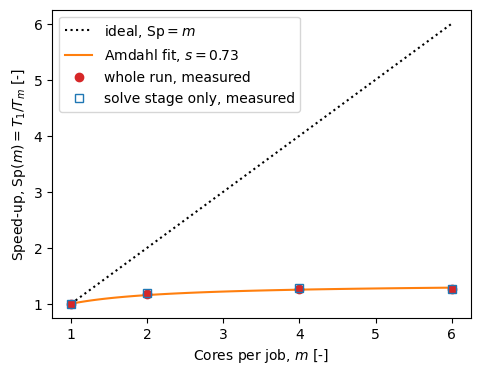

In [7]:
def amdahl(m, s):
    """Amdahl speed-up 1 / (s + (1 - s)/m) for sequential fraction s on m cores."""
    # The sequential part s stays; the rest, 1 - s, is shared by m cores.
    return 1.0 / (s + (1.0 - s) / m)


# Cores m, the mean wall time T_m, the mean solve time and the mean process-tree CPU time for each core count [s], and the tokens per job.
cores = np.array(CORES_TESTED, dtype=float)
# Mean wall time over the two repeats, for each core count.
wall = np.array([np.mean([r["wall_s"] for r in bench[c]]) for c in CORES_TESTED])
# Mean duration of the solve stage alone.
solve = np.array([np.mean([stage_seconds(r)["solve"] for r in bench[c]]) for c in CORES_TESTED])
# Mean CPU time of the whole process tree.
cpu_tree = np.array([np.mean([r["driver_cpu_s"] for r in bench[c]]) for c in CORES_TESTED])
# Licence tokens of one job, as the job log reports them.
tokens = [bench[c][0]["tokens"] for c in CORES_TESTED]
# Speed-up Sp(m) = T_1 / T_m of the whole run and of the solve stage alone.
speedup = wall[0] / wall
speedup_solve = solve[0] / solve

# Fit the sequential fraction s (between 0 and 1) to the whole-run speed-up.
(s_fit,), _ = curve_fit(amdahl, cores, speedup, p0=[0.3], bounds=(0.0, 1.0))

# Table of the measurements.
print("   m   wall [s]   Sp(m) run   Sp(m) solve   CPU time [s]   tokens")
for i, c in enumerate(CORES_TESTED):
    print("  %2d   %7.1f   %9.2f   %11.2f   %12.1f   %6s" % (c, wall[i], speedup[i], speedup_solve[i], cpu_tree[i], tokens[i]))
print("\nAmdahl fit to the whole-run speed-up: s = %.2f, so Sp(m) can never exceed 1/s = %.1f" % (s_fit, 1.0 / s_fit))

# Measured speed-ups against the ideal line and the fitted curve.
m_line = np.linspace(1, 6, 100)
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(m_line, m_line, "k:", label="ideal, $\\mathrm{Sp}=m$")
ax.plot(m_line, amdahl(m_line, s_fit), "C1-", label="Amdahl fit, $s=%.2f$" % s_fit)
ax.plot(cores, speedup, "o", color="C3", label="whole run, measured")
ax.plot(cores, speedup_solve, "s", color="C0", mfc="none", label="solve stage only, measured")
# Axis labels and legend.
ax.set_xlabel("Cores per job, $m$ [-]")
ax.set_ylabel("Speed-up, $\\mathrm{Sp}(m)=T_1/T_m$ [-]")
ax.legend()
plt.show()

Extra cores help little. Two cores take the run from 302.8 s to 258.7 s (speed-up 1.17), four to 238.5 s (1.27), and
six give 239.6 s (1.26), no better than four. Efficiency is only 0.58 on two cores and 0.21 on six. The price grows
steadily: the CPU time the job consumes rises from 289 s to 380 s, 554 s and 796 s, and the licence tokens it draws
from 50 to 94.

What does $s=0.73$ mean? In Amdahl's words, it is the portion of the total time that is sequential and cannot be parallelized. This means that about three quarters of the total time is spent on tasks that cannot be done in parallel. Indeed, the solve stage alone speeds up by the same factors as the whole run, so this sequential part sits inside the solver, not in the start-up or the extraction. The solver's message file says that it shares out the *element operations* among the threads. We can then infer that that our current model is too small for that to pay: mesh M1 has 1,200 shell elements and 1,280 nodes, about 7,700 degrees of freedom, so the element work of one increment is short. The rest of each increment, together with the cost of coordinating the threads, then makes up most of the time. A larger model spends a larger share of its time on the elements and would scale better.

The consequence for the campaign is clear: one core per job is the better use of a core for the current mesh, and the way to go faster is to run **many single-core jobs at once**.

### Step 4 &ndash; Does running several jobs side by side help?

One job gains little from extra cores, so we try the other way: $k$ single-core jobs at once. To measure the
effect of $k$ alone, every job is the **same** analysis, the nominal sample. Samples with other inputs take different
times even alone, which would blur the
comparison. The design file `design_nominal_x12.csv` holds 12 copies of the nominal row, and we run **waves** of
$k=1,2,3,4,6,8,11,12$ jobs, each wave starting only after the previous one has finished. The driver launched the jobs
of a wave five seconds apart (its default at the time), so that they do not all ask the licence server for tokens in the same second.

These runs use the current driver, which solves a prepared input file instead of building the model with Abaqus/CAE
each time (Step 5 and Part 3 explain why), so a job alone takes a few seconds less than in Step 2.

Before looking at the numbers, make a guess: with 6 physical cores, what throughput gain do you expect from 6 jobs at
once, and from 12?

The cell below writes (or checks) the 12-row design, makes sure every wave's results exist, and prints for each wave
the mean wall time $T(k)$ of one job with its range, the solver's own CPU time per job (from its `.dat` file), the
wall time of the whole wave (first launch to last finish), and the throughput gain $G(k)$ with the efficiency $G/k$.

In [8]:
# The 12-row nominal design: every row has every input at its mean (Part 1), so every job is the same analysis.
NOMINAL_X12_CSV = RUNS / "design_nominal_x12.csv"
print("design_nominal_x12.csv:", write_or_check_design(NOMINAL_X12_CSV, np.tile(INPUT_MEANS, (12, 1))))
# The wave sizes k; wave k runs rows 0 to k-1 with k workers, into its own folder.
WAVE_SIZES = (1, 2, 3, 4, 6, 8, 11, 12)
for k in WAVE_SIZES:
    run_or_load(NOMINAL_X12_CSV, list(range(k)), RUNS / "waves_nominal" / ("k%d" % k), workers=k, cpus=1,
                allow_run=RUN_CAMPAIGN)
# Load every wave: a list of k results for each k.
waves = {k: load_results(RUNS / "waves_nominal" / ("k%d" % k), list(range(k))) for k in WAVE_SIZES}

# Mean wall time of one job in each wave, T(k) [s]; T(1) is the job alone.
wall_mean = {k: np.mean([j["wall_s"] for j in jobs]) for k, jobs in waves.items()}
# Throughput gain G(k) = k T(1) / T(k).
gain = {k: k * wall_mean[1] / wall_mean[k] for k in WAVE_SIZES}

print("\n  k   T(k) [s]   shortest-longest [s]   solver CPU [s]   wave wall [s]   G(k)   G/k")
for k, jobs in waves.items():
    # Wall times of the k jobs, the solver's own CPU time, and the wave's span from first launch to last finish [s].
    walls = [j["wall_s"] for j in jobs]
    cpu = np.mean([j["cpu_seconds"] for j in jobs])
    span = max(j["t_launch"] + j["wall_s"] for j in jobs) - min(j["t_launch"] for j in jobs)
    print("%3d   %8.1f   %8.1f - %-8.1f   %14.1f   %13.0f   %4.2f   %4.2f"
          % (k, wall_mean[k], min(walls), max(walls), cpu, span, gain[k], gain[k] / k))
# Every job is the same analysis: the number of increments must be the same in all of them.
print("\nIncrements per job: %s" % sorted({j["n_increments"] for jobs in waves.values() for j in jobs}))

design_nominal_x12.csv: checked against the file on disk
k1: all 1 results present.
k2: all 2 results present.
k3: all 3 results present.
k4: all 4 results present.
k6: all 6 results present.
k8: all 8 results present.
k11: all 11 results present.
k12: all 12 results present.



  k   T(k) [s]   shortest-longest [s]   solver CPU [s]   wave wall [s]   G(k)   G/k
  1      299.5      299.5 - 299.5               269.0             300   1.00   1.00
  2      300.9      300.3 - 301.4               278.0             307   1.99   1.00
  3      310.8      309.8 - 311.8               288.0             324   2.89   0.96
  4      319.7      318.2 - 321.2               296.8             338   3.75   0.94
  6      379.4      376.8 - 381.5               354.0             409   4.74   0.79
  8      466.9      460.7 - 471.8               435.8             506   5.13   0.64
 11      623.9      611.1 - 633.1               575.5             682   5.28   0.48
 12      665.6      655.2 - 673.1               598.4             730   5.40   0.45

Increments per job: [415]


Every job is the same analysis, and it behaves like it: all 47 jobs took 415 increments, and within a wave the
wall times differ by at most 3% (611 to 633 s at $k=11$). So the differences between the waves are the effect of $k$
alone.

Up to 4 jobs, running side by side costs almost nothing: $T(k)$ goes from 299.5 s alone to 301 s at $k=2$, 311 s at
3 and 320 s at 4, so $G$ is 1.99, 2.89 and 3.75 and the efficiency $G/k$ stays at 0.94 or above. At $k=6$, one job per
physical core, each job takes 379 s, 27% more than alone, and $G=4.74$. Beyond the physical cores the jobs share
cores through hyper-threading and slow down sharply: 467 s at 8, 624 s at 11 and 666 s at 12. The gain then grows
only from 4.74 to 5.13, 5.28 and 5.40. If you guessed close to 6 and 12, the first guess is nearly right and the second
is far off. The solver's own CPU time per job grows with the wall time (269 s alone, 576 s at $k=11$): sharing a
core, the processor does the same work more slowly.

The same results as a figure. On the left, the wall time of **every** job (grey dots) and the wave means (red), with
the job alone as a dashed line. On the right, the throughput gain $G(k)$ against the ideal $G=k$, with the 6 physical
cores and the 12 logical processors marked.

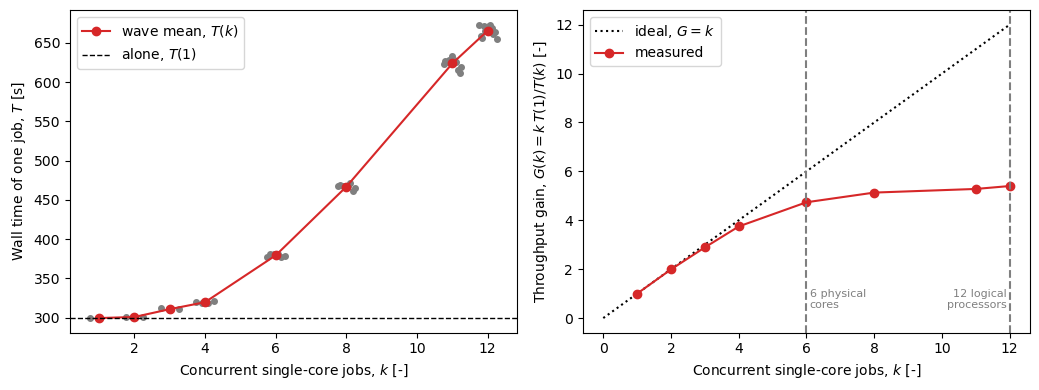

In [9]:
# Wave sizes, and a two-panel figure: job wall times on the left, throughput gain on the right.
ks = np.array(WAVE_SIZES)
fig, (ax_t, ax_g) = plt.subplots(1, 2, figsize=(10.5, 4.0))
# Left: one grey dot per job (small horizontal offsets so that dots do not overlap), the wave means, and T(1).
for k in ks:
    walls = [j["wall_s"] for j in waves[k]]
    ax_t.plot(k + np.linspace(-0.25, 0.25, len(walls)), walls, "o", color="C7", ms=4)
ax_t.plot(ks, [wall_mean[k] for k in ks], "o-", color="C3", label="wave mean, $T(k)$")
ax_t.axhline(wall_mean[1], color="k", ls="--", lw=1, label="alone, $T(1)$")
# Labels for the left panel.
ax_t.set_xlabel("Concurrent single-core jobs, $k$ [-]")
ax_t.set_ylabel("Wall time of one job, $T$ [s]")
ax_t.legend(loc="upper left")
# Right: the ideal line G = k and the measured gains.
ax_g.plot([0, 12], [0, 12], "k:", label="ideal, $G=k$")
ax_g.plot(ks, [gain[k] for k in ks], "o-", color="C3", label="measured")
# Mark the 6 physical cores and the 12 logical processors of the desktop.
ax_g.axvline(6, color="C7", ls="--")
ax_g.text(6.1, 0.4, "6 physical\ncores", color="C7", fontsize=8)
ax_g.axvline(12, color="C7", ls="--")
ax_g.text(11.9, 0.4, "12 logical\nprocessors", color="C7", fontsize=8, ha="right")
# Labels and legend for the right panel.
ax_g.set_xlabel("Concurrent single-core jobs, $k$ [-]")
ax_g.set_ylabel("Throughput gain, $G(k)=k\\,T(1)/T(k)$ [-]")
ax_g.legend(loc="upper left")
fig.tight_layout()
plt.show()

On the left, the wall time of one job is flat up to $k=4$, bends upward at 6 and then rises almost in a straight line
to 12. The dots of each wave lie within a few seconds of each other, so the trend is not scatter. On the right, the
gain follows the ideal $G=k$ up to 4, falls below it at 6, and almost flattens beyond the 6 physical cores: from 6 to
12 jobs it grows by only 0.66, about 0.11 of a job for each extra job. For this solver the physical cores set the
throughput, and the logical processors add little.

> **Pitfall:** our first version of this measurement ran a *different* validation sample in every job and divided
> each job's wall time by its number of increments, to make samples of different lengths comparable. It gave
> $G(12)=6.1$ instead of 5.4, and about 0.27 of a job for each job beyond 6 instead of 0.11. The normalisation did not
> remove the differences between samples (an increment after the peak, with much damage, costs more than one before
> it), and the scatter it left was as large as the effect being measured. Measuring with one identical job removes
> the question.

### Step 5 &ndash; What limits $k$, and how long would the campaign take?

Three things can stop us from simply raising $k$: the cores, the memory and the licences.

- **Cores.** Step 4 shows whether jobs beyond the physical cores still add throughput. We keep one logical processor
  free for the machine itself, so the core limit is the number of logical processors minus one.
- **Memory.** Every job needs memory for its whole process tree (the Abaqus launcher, the solver, the extraction). The
  memory limit is the machine's memory divided by the largest of these.
- **Licences.** Abaqus is licensed per job, by *tokens* drawn from a pool shared with other users. A run that builds
  its model in Abaqus/CAE holds a CAE licence *and* a solver licence for the whole job, so the smaller of the two pools
  can cap $k$. Writing the model once as a **template input file** and giving each sample a copy with its own material
  values removes the CAE licence from every job: the job then needs only solver tokens, and it also skips the CAE
  start-up of Step 2. The current driver works this way (Part 3). The free tokens change during the day, so the driver
  checks them before every launch instead of fixing a limit in advance.

The **concurrency limit** is the smallest of the limits,

$$k_{\max}=\min\!\Big(\text{logical processors}-1,\ \ \Big\lfloor\frac{\text{RAM}}{\text{peak RAM per job}}\Big\rfloor,\ \ \text{licence limit}\Big),$$

where $\lfloor\cdot\rfloor$ rounds down. The cell computes the first two for the desktop, from its specification and
the largest process-tree memory of any wave job.

In [10]:
# The desktop of the measurements: 12 logical processors and 64 GB of RAM [MB] (Dell OptiPlex 5060, Intel Core i7-8700).
DESKTOP_LOGICAL, DESKTOP_RAM_MB = 12, 64 * 1024
# Largest process-tree memory of any wave job [MB] (template input file, as in the campaign).
peak_ram_mb = max(j["peak_ram_mb"] for jobs in waves.values() for j in jobs)
# The core and memory limits on the number of concurrent jobs, and the smaller of the two.
limits = {"processors (logical - 1)": DESKTOP_LOGICAL - 1, "memory": int(DESKTOP_RAM_MB // peak_ram_mb)}
K_DESKTOP = min(limits.values())
# Report the memory, each limit, and k_max.
print("Largest process-tree memory of a job: %.0f MB of %.0f MB" % (peak_ram_mb, DESKTOP_RAM_MB))
for name, value in limits.items():
    # One line per limit.
    print("  limit from %-24s %4d concurrent jobs" % (name + ":", value))
print("k_max on the desktop = %d" % K_DESKTOP)

Largest process-tree memory of a job: 369 MB of 65536 MB
  limit from processors (logical - 1):   11 concurrent jobs
  limit from memory:                   177 concurrent jobs
k_max on the desktop = 11


Memory is no constraint here: the largest job used 369 MB, so the desktop's 64 GB would hold 177 jobs. The cores set
the limit, $k_{\max}=11$. Is the eleventh job worth it, when the gain barely grows past 6? A little: $G(11)=5.28$
against $G(6)=4.74$ is 11% more throughput, at the price of a machine that is fully busy. The licence limit is not
computed: with a template input file each job needs only solver tokens, and the driver waits for them before every
launch (Part 3).

Now the estimate. With $k$ jobs running, the machine finishes $G(k)$ jobs in the time one job alone takes, $T(1)$. A
campaign of $n$ runs therefore takes about

$$T_{\text{campaign}}\approx\frac{n\,T(1)}{G(k_{\max})},$$

where $n$ is the number of runs, $T(1)$ the wall time of one job alone [s] and $G(k_{\max})$ the throughput gain at the
concurrency limit (Step 4). For the desktop, $G(11)$ was measured. For a larger machine we can only extrapolate. Take
a hypothetical workstation-class server with 60 physical cores and 120 logical processors, ten times the desktop's 6
and 12, so $k_{\max}=119$ if memory and licences allow. If it behaves like ten desktops side by side, its gain is about
$10\,G(11)$.

These are estimates of the right size, not predictions to the minute. A faster or slower processor changes $T(1)$
itself, and the estimate scales with it; the samples of the design take somewhat different times from the nominal
one; and at the end of a campaign some processors sit idle while the last long jobs finish. The cell computes the
estimate for each of the three stages of Part 1 and for all 9,892 runs.

In [11]:
# The campaign in its three stages: the training runs each added (the validation runs with the first), Part 1.
stage_runs = {"stage 1 (n_p = 2) + validation": 1632 + VALIDATION_RUNS, "stage 2 (n_p = 4)": 1632, "stage 3 (n_p = 12)": 6528}
# The three stages add up to the whole campaign.
assert sum(stage_runs.values()) == N_TRAIN_MAX + VALIDATION_RUNS
# The hypothetical server as a multiple of the desktop: 60/6 physical cores and 120/12 logical processors.
SERVER_SCALE = 10
# Estimated wall times of each stage: one job at a time, the desktop at k_max, and the server as ten desktops.
print("%-32s %6s %16s %12s %10s" % ("", "runs", "one at a time", "desktop", "server"))
# One row per stage, and one for the whole campaign.
for label, n in list(stage_runs.items()) + [("all", N_TRAIN_MAX + VALIDATION_RUNS)]:
    # One job at a time: n T(1); the desktop and the server divide it by their throughput gain.
    t_serial = n * wall_mean[1]
    print("%-32s %6d %16s %10.0f h %8.1f h" % (label, n, human_time(t_serial), t_serial / gain[K_DESKTOP] / 3600.0,
                                               t_serial / (SERVER_SCALE * gain[K_DESKTOP]) / 3600.0))
# The inputs of the estimate.
print("(T(1) = %.0f s; desktop k = %d, G = %.2f; server k = 119, G ~ %.0f)"
      % (wall_mean[1], K_DESKTOP, gain[K_DESKTOP], SERVER_SCALE * gain[K_DESKTOP]))

                                   runs    one at a time      desktop     server
stage 1 (n_p = 2) + validation     1732           6 days         27 h      2.7 h
stage 2 (n_p = 4)                  1632           6 days         26 h      2.6 h
stage 3 (n_p = 12)                 6528          23 days        103 h     10.3 h
all                                9892          34 days        156 h     15.6 h
(T(1) = 300 s; desktop k = 11, G = 5.28; server k = 119, G ~ 53)


One job at a time, the 9,892 runs would take 34 days, a little less than Part 1's 45 because the measured $T(1)$,
300 s, is below NB6's 390 s. On the desktop at $k_{\max}=11$ they take an estimated 156 h, more than six days, and the
hypothetical server cuts that to about 16 h. Stage by stage, the server needs about 2.7 h for the first stage, 2.6 h
for the second and 10.3 h for the third: each one an overnight run, which is what made it reasonable to grow the
campaign in stages. The range from desktop to server is the factor of ten we assumed between them. Both numbers carry
the caveats above: in particular, a server whose cores are faster or slower than the desktop's changes $T(1)$, and the
estimate with it. Part 3, Step 4 compares the server estimates with the real batches.

## Part 3 &ndash; Running the campaign

### Step 1 &ndash; The design: one random stream, nested

The list of input values at which the model is run is called the **design of experiments**, or simply the **design**, a term from experimental science, where one plans which experiments to carry out. Here the design is a table with one row per Abaqus run and one column per uncertain input. We fill it with **plain random samples**, as Thapa et al. do: each row is a draw of 15 independent standard normals $\boldsymbol\xi$, turned into physical inputs by the transform of Part 1.

Because the campaign grew in stages, the design has to grow without wasting the runs already made. So the training set is **one** random stream (seed 7), and each stage runs its next rows: rows 0&ndash;1,631 for $n_p=2$, 1,632&ndash;3,263 for $n_p=4$ and 3,264&ndash;9,791 for $n_p=12$. NumPy's generator gives the same first rows whatever the length requested, so lengthening the stream changes no row already run, and any start of it is itself a random design of that size. The same property serves the fits: orders 1 and 2 use the first rows of the same stream, and NB10 fits on growing starts of it to see how the error falls as runs are added. The 100 validation rows come from a separate stream (seed 8) and are shared by every order.

The cell below generates the two designs, training and validation, and saves each as a CSV file, `runs/nb09/design_train.csv` and `design_validation.csv`, in the physical units of Part 1, with `write_or_check_design` (Part 2): an existing file is checked, never overwritten. It then checks that the stream drawn only as long as each earlier stage gives the first rows of the full stream, and prints the realised mean and CoV of each input over the 9,792 training rows.

In [12]:
# The two design streams (seeds from the series' seed table), the rows of the training stream, and where results are saved.
SEED_DESIGN_TRAIN, SEED_DESIGN_VALID = 7, 8
def make_design(seed, n_rows):
    """n_rows x d standard-normal draws xi from one seeded stream, and the matching physical inputs x."""
    # One generator per stream; the draws come out row by row, so a shorter request is a prefix of a longer one.
    xi = np.random.default_rng(seed).standard_normal((n_rows, D))
    return xi, physical_inputs(xi)


# Generate the training and validation designs, and write or check their files.
xi_train, x_train = make_design(SEED_DESIGN_TRAIN, N_TRAIN_MAX)
xi_valid, x_valid = make_design(SEED_DESIGN_VALID, VALIDATION_RUNS)
print("design_train.csv     :", write_or_check_design(RUNS / "design_train.csv", x_train))
print("design_validation.csv:", write_or_check_design(RUNS / "design_validation.csv", x_valid))

# Nesting: the stream drawn only as long as stage 1 (n_p = 2) and stage 2 (n_p = 4) gives the first rows of the full one.
for n_rows in (1632, 3264):
    assert np.array_equal(make_design(SEED_DESIGN_TRAIN, n_rows)[0], xi_train[:n_rows])
print("nesting holds: rows 0-1631 are the stage-1 design, rows 0-3263 the stage-2 design\n")

# Realised mean and CoV of every input over the training rows, beside the nominal mean.
print("%-5s %12s %14s %10s" % ("input", "nominal mean", "realised mean", "realised CoV"))
for k, name in enumerate(INPUT_NAMES):
    # The column of this input, and one table row: nominal mean, realised mean, realised CoV (sample std over mean).
    col = x_train[:, k]
    print("%-5s %12.4g %14.4g %12.3f" % (name, INPUT_MEANS[k], col.mean(), col.std(ddof=1) / col.mean()))

design_train.csv     : checked against the file on disk
design_validation.csv: checked against the file on disk
nesting holds: rows 0-1631 are the stage-1 design, rows 0-3263 the stage-2 design

input nominal mean  realised mean realised CoV
E1       1.724e+05      1.724e+05        0.100
E2        1.03e+04       1.03e+04        0.099
nu12          0.32         0.3201        0.101
G12           5520           5513        0.101
G23           3450           3447        0.100
X_T           2826           2831        0.100
X_C           1620           1618        0.100
Y_T           65.5          65.45        0.099
Y_C            248          247.9        0.100
S_L            122            122        0.099
S_T            122          122.1        0.099
G_fT          81.5          81.54        0.101
G_fC         106.3          106.3        0.100
G_mT        0.2774         0.2774        0.100
G_mC        0.7879         0.7885        0.100


The files already existed (had they not, the cell would have written them), and the check passed: their numbers match the freshly generated ones to within rounding, a relative difference below $10^{-12}$, so the seeds still give the same design. The nesting check passed too: the 1,632 rows of stage 1 are the first rows of the 3,264 of stage 2, which are the first rows of the 9,792 of stage 3.

The realised statistics match the design target. Every mean is within 0.2% of its nominal value, and every CoV is between 0.099 and 0.101 against the target 0.100, the sampling scatter expected for 9,792 draws. So the transform $x=\mu(1+0.1\,\xi)$ and the random stream behave as intended, and the inputs are ready to be sent to Abaqus.

### Step 2 &ndash; What the driver does

Every run of this notebook goes through one script, `scripts/oht_campaign.py`. It is plain Python 3 and never runs
inside Abaqus, so it works unchanged on Windows and Linux. For a design file and a range of its rows it does the
following.

1. **Template, once.** If `runs/nb09/template/M1.inp` is missing, it runs NB6's build script once in Abaqus/CAE to
   write the model of mesh M1 as an input file, without solving it.
2. **One copy per sample.** For each row it copies the template into the sample's own folder and replaces the three
   lines that hold the material values (elastic constants, Hashin strengths, fracture energies) with the row's 15
   inputs, $G_{13}=G_{12}$ included.
3. **Solve and extract.** It runs `abaqus job=` on the copy and then `abaqus python extract_open_hole_tension.py`,
   which reads the output database and writes the results. Neither command holds a CAE licence.
4. **Save.** It writes `sNNNN.json` (the inputs, the load&ndash;displacement curve, the energies, the outputs, the
   timings) and one line of `status.csv`, and deletes the job's working files. If the job stopped early, it first
   removes the solver's failed last frame (Part 4, Step 1).

It runs up to `--workers` samples at once (by default the logical processors minus one, or fewer if memory is short),
and before each launch it asks the licence server whether the solver pools have a job's tokens free, on top of an
optional reserve left for other users (`--reserve 0.1` keeps 10% of each pool free; there is none by default); if
not, it waits a minute and asks again. Launches are at least `--stagger` seconds apart (1 s by default), and a job
launched less than 30 s ago counts as holding its tokens, because a job checks them out only some seconds after
it starts. A
sample whose JSON exists is skipped, so an interrupted campaign is resumed by running the same command again; a job
that got no licence leaves no JSON and is retried the same way.

### Step 3 &ndash; Running it on a desktop or on a server

Step 1 writes the two design files into `runs/nb09/`; the folder is not in the repository, so run this notebook up to
Step 1 first. Then, on a **desktop**, from the repository's root folder in a terminal where `abaqus` runs (on Windows,
an Anaconda Prompt; if `abaqus` is not on the `PATH`, add `--abaqus C:\SIMULIA\Commands\abaqus.bat`):

```bash
conda activate progressive-damage-uq
python scripts/oht_campaign.py --selftest           # checks the driver's own functions, no Abaqus needed
python scripts/oht_campaign.py                      # the training design into runs/nb09/train
python scripts/oht_campaign.py --design runs/nb09/design_validation.csv --out-dir runs/nb09/validation
```

On a **server** without a job scheduler, start the campaign inside `tmux`, which keeps it running after the terminal
closes. The module names depend on the server:

```bash
tmux new -s nb09                    # detach with Ctrl-b d, reattach with: tmux attach -t nb09
module load abaqus/2023 miniconda3  # the server's Abaqus and conda
which abaqus                        # if only abq2023 exists, add --abaqus abq2023 to the commands below
abaqus information=release          # must be 2023, to match the model
nproc; free -g                      # logical processors and memory: the driver's upper limit on k
git clone <this repository> && cd progressive-damage-uq-jupyter
eval "$(conda shell.bash hook)"     # makes `conda activate` work in this shell
conda env create -f environment.yml && conda activate progressive-damage-uq
# copy runs/nb09/design_train.csv from the machine that ran Step 1
python scripts/oht_campaign.py --selftest
python scripts/oht_campaign.py --rows 0 --out-dir runs/nb09/server_check --workers 1   # smoke test: template + row 0
python scripts/oht_campaign.py 2>&1 | tee -a runs/nb09/train_server.log
# repeat the last command until it reports "0 of 9792 samples to run", then copy runs/nb09/train/ back
```


### Step 4 &ndash; Where the runs were made, and how long they took

The 9,792 training runs were made on such a server, a high-performance workstation with 60 physical cores and 120
logical processors that we share with other users. We ran them in three batches, one per stage of
Part 1, each when the server was free, all with 119 workers:

- **batch 1**, rows 0&ndash;1631 ($n_p=2$), launched five seconds apart and keeping 10% of each licence pool free, the
  driver's defaults at the time;
- **batch 2**, rows 1632&ndash;3263 ($n_p=4$), launched one second apart and with no reserve, so that it could take
  every free solver token;
- **batch 3**, rows 3264&ndash;9791 ($n_p=12$), also launched one second apart.

The 100 validation runs were run on the desktop of Part 2, in several batches, with the earlier version of the driver
that built every model in Abaqus/CAE. That version wrote the material values into the input file rounded to 6
significant digits, a relative change of at most $10^{-6}$ in each input, which is far below anything the surrogate
can resolve.

The next cell checks that every result exists (with `RUN_CAMPAIGN = False` it only prints the command for a missing
one) and loads them. For each campaign it then reports the time during which at least one of its jobs was running
(so that pauses between batches do not count), the mean wall time of one job, how many jobs ran on average and at
most, the median time between two launches, the solver's CPU time per load increment (from its `.dat` file),
which tells whether each job ran slower or simply took more increments, and, for the server batches, Part 2's
estimate for the hypothetical server.

In [13]:
# The design files and the rows of each campaign: all 9,792 training rows and all 100 validation rows.
TRAIN_CSV, VALID_CSV = RUNS / "design_train.csv", RUNS / "design_validation.csv"
TRAIN_ROWS, VALID_ROWS = list(range(N_TRAIN_MAX)), list(range(VALIDATION_RUNS))
# Make sure every result exists (or print the command), then load them all.
run_or_load(TRAIN_CSV, TRAIN_ROWS, RUNS / "train", workers=K_DESKTOP, allow_run=RUN_CAMPAIGN)
run_or_load(VALID_CSV, VALID_ROWS, RUNS / "validation", workers=K_DESKTOP, allow_run=RUN_CAMPAIGN)
train_results = load_results(RUNS / "train", TRAIN_ROWS)
valid_results = load_results(RUNS / "validation", VALID_ROWS)


def busy_seconds(results):
    """Time during which at least one job of a campaign was running [s].

    Parameters
    ----------
    results : list of dict
        Result files, each with its launch time `t_launch` and wall time `wall_s` [s].

    Returns
    -------
    float
        Length of the union of the intervals [t_launch, t_launch + wall_s] [s].
    """
    # The jobs' intervals, sorted by start time.
    intervals = sorted((r["t_launch"], r["t_launch"] + r["wall_s"]) for r in results)
    total, (start, end) = 0.0, intervals[0]
    for a, b in intervals[1:]:
        if a > end:
            # A gap: close the current busy stretch and start a new one.
            total, start, end = total + (end - start), a, b
        else:
            # Overlap: extend the current busy stretch.
            end = max(end, b)
    # Add the last stretch.
    return total + (end - start)


def most_running(results):
    """Largest number of jobs of a campaign running at the same moment [-]."""
    # +1 at every launch and -1 at every finish, in time order: their running sum counts the jobs running.
    events = sorted([(r["t_launch"], 1) for r in results] + [(r["t_launch"] + r["wall_s"], -1) for r in results])
    return int(max(np.cumsum([step for _, step in events])))


# The three training batches (rows 0-1631, 1632-3263 and 3264-9791) and the validation runs.
BATCHES = {"training, batch 1 (server)": range(0, 1632), "training, batch 2 (server)": range(1632, 3264),
           "training, batch 3 (server)": range(3264, N_TRAIN_MAX)}
campaigns = {label: [train_results[i] for i in rows] for label, rows in BATCHES.items()}
campaigns["validation (desktop)"] = valid_results
print("%-27s %5s %8s %9s %10s %15s %14s %18s" % ("campaign", "runs", "busy", "estimate", "mean job", "jobs running",
                                                 "launch every", "solver CPU per"))
print("%-27s %5s %8s %9s %10s %15s %14s %18s" % ("", "", "[h]", "[h]", "[s]", "mean   max", "[s], median",
                                                 "increment [s]"))
for label, results in campaigns.items():
    # Busy time, and the mean number of jobs running: total job time over busy time.
    busy = busy_seconds(results)
    running = sum(r["wall_s"] for r in results) / busy
    # Median time between two successive launches, and the solver's mean CPU time per load increment.
    launch_step = np.median(np.diff(np.sort([r["t_launch"] for r in results])))
    cpu_per_inc = np.mean([r["cpu_seconds"] / r["n_increments"] for r in results])
    # Part 2's estimate on the hypothetical server (server batches only).
    estimate = len(results) * wall_mean[1] / (SERVER_SCALE * gain[K_DESKTOP]) / 3600.0 if "server" in label else np.nan
    print("%-27s %5d %8.2f %9.1f %10.0f %8.0f %6d %14.1f %18.2f" % (label, len(results), busy / 3600.0, estimate,
          np.mean([r["wall_s"] for r in results]), running, most_running(results), launch_step, cpu_per_inc))
# The estimate of Part 2, Step 5, for all training runs on the hypothetical server, and the batches' busy time.
print("\nPart 2's estimate for the %d training runs on the server: %.1f h; the three batches were busy for %.1f h"
      % (N_TRAIN_MAX, N_TRAIN_MAX * wall_mean[1] / (SERVER_SCALE * gain[K_DESKTOP]) / 3600.0,
         sum(busy_seconds(campaigns[label]) for label in BATCHES) / 3600.0))

train: all 9792 results present.
validation: all 100 results present.


campaign                     runs     busy  estimate   mean job    jobs running   launch every     solver CPU per
                                       [h]       [h]        [s]      mean   max    [s], median      increment [s]
training, batch 1 (server)   1632     2.71       2.6        353       59     82            5.5               0.74
training, batch 2 (server)   1632     5.93       2.6        663       51     71            2.0               1.35
training, batch 3 (server)   6528    23.96      10.3        611       46     77            1.9               1.25
validation (desktop)          100     2.68       nan        635        7     11           17.7               1.30

Part 2's estimate for the 9792 training runs on the server: 15.4 h; the three batches were busy for 32.6 h


Batch 1 kept the server busy for 2.71 h for its 1,632 runs, close to Part 2's estimate of 2.6 h. The server never ran 119 jobs at once: on average 59 were
running, and 82 at most. The driver launched one job at a time, five seconds apart plus the licence query, so a job
was launched every 5.5 s, and with jobs lasting 353 s on average only about $353/5.5\approx64$ could be running at
any moment, whatever the number of workers allowed. The batch was limited by the launch pace, not by the cores, which
is why the later batches launched one second apart.

That alone did not make them faster. Batches 2 and 3 launched a job every 2.0 and 1.9 s, so up to about
$611/1.9\approx320$ jobs could have been running, yet on average only 51 and 46 were. The driver's logs show that it
waited for free licence tokens 260 times in batch 2 and 1,167 times in batch 3: the university's shared pool, not the
launch pace, capped them. They took 5.93 and 23.96 h, against estimates of 2.6 and 10.3 h. Each job also ran slower, 663 and 611 s on average
against 353 s in batch 1. The solver
needed 1.35 and 1.25 s of CPU time per load increment against 0.74 s, so it did the same work about 1.7 to 1.8 times
more slowly. Fewer of our own jobs were running than in batch 1, so they cannot be the cause; the server was
presumably busy with other users' work, which we did not record.

Altogether the 9,792 training runs kept the server busy for 32.6 h, about twice Part 2's estimate of 15.4 h. The
lesson for planning is that Part 2's estimate holds for an otherwise idle machine with free licences; on a shared
one, the same work can take twice as long or more.

The validation runs kept the desktop busy for 2.7 h, with 7 jobs running on average. They were made in the waves
of the first version of Part 2, Step 4 (1 to 12 jobs at a time, see the Pitfall there) and one batch of 64 jobs at
$k=11$, so their time does not measure any single setting.

## Part 4 &ndash; Checking the runs

A surrogate fitted to a wrong run learns the wrong thing, and nothing in the fit would show it. So before any fit we
check the 9,892 results: that each one belongs to its design row, and that each one gives a trustworthy first-ply
failure and peak.

### Step 1 &ndash; What do the runs look like?

Our first look at the runs found one training run, s2632, with a load of $-4.5\times10^{11}$ N in its last frame.
That frame sits at the same displacement as the frame before it: it is the solver's last, failed attempt to
converge, written to the output before the job stopped. Searching all runs for the same pattern, we found it at the
end of **every** job that stopped early. Usually the load of that frame equals the previous one, but in a few runs it
is garbage, and where the garbage is higher than the true peak, the extraction took it as the peak. The driver now
removes that frame and finds the peak again (`drop_failed_frame`).

The next cell counts the jobs that stopped before the end displacement $U_2=1.3$ mm and those of them whose last two
frames share one displacement, and lists the runs whose last load is more than double the previous one, or negative,
with the frame of the peak as extracted. It then removes the failed frame from every run and draws the
load&ndash;displacement curve of every training and validation run as a thin, faint grey line, so that the grey
darkens where many curves overlap, with the curve of the nominal sample as a black line on top.

1090 of 9892 runs stopped before U2 = 1.3 mm; 1090 of them end with two frames at one displacement
  s1435: last frame 1.1e+04 N, previous 4079 N, at U2 = 1.2610 mm; extracted peak 33978 N in frame 192 of 435
  s2632: last frame -4.5e+11 N, previous 5418 N, at U2 = 0.7147 mm; extracted peak 36087 N in frame 85 of 156
  s2747: last frame 5.34e+03 N, previous 2312 N, at U2 = 0.6530 mm; extracted peak 41242 N in frame 63 of 139
  s4329: last frame 5.56e+04 N, previous 4532 N, at U2 = 1.1570 mm; extracted peak 55555 N in frame 345 of 346
  s4447: last frame 1.06e+04 N, previous 2148 N, at U2 = 0.7681 mm; extracted peak 33949 N in frame 517 of 723
  s5285: last frame 2.89e+04 N, previous 4488 N, at U2 = 1.1129 mm; extracted peak 33604 N in frame 264 of 534
  s6738: last frame 3.11e+04 N, previous 5392 N, at U2 = 0.9568 mm; extracted peak 31547 N in frame 275 of 1060
  s8121: last frame 1.53e+04 N, previous 3299 N, at U2 = 0.9766 mm; extracted peak 32723 N in frame 104 of 497
  s8425: last f

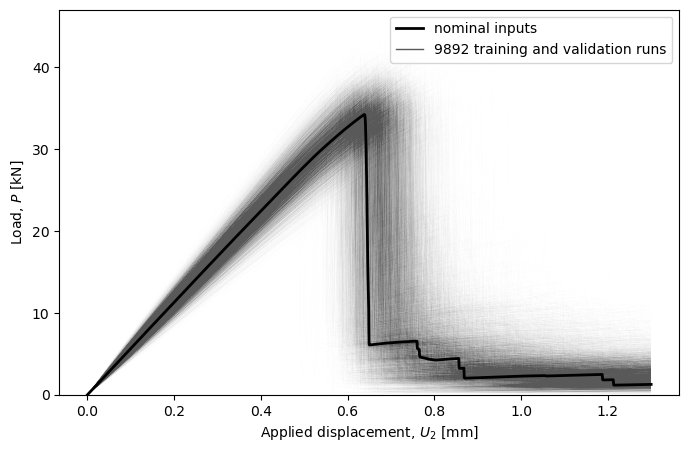

peaks 13.8-44.8 kN (1st-99th percentile 29.5-40.7 kN), at U2 = 0.25-0.97 mm; nominal 34.3 kN


In [14]:
# The nominal sample's curve (every input at its mean): the k = 1 job of Part 2, Step 4.
nominal = waves[1][0]
# Every training and validation run, training first; the jobs that stopped early; those ending on a repeated displacement.
all_results = train_results + valid_results
unfinished = [r for r in all_results if not r["completed"]]
repeated = [r for r in unfinished if r["u2"][-1] == r["u2"][-2]]
print("%d of %d runs stopped before U2 = %.1f mm; %d of them end with two frames at one displacement"
      % (len(unfinished), len(all_results), nominal["u2_target"], len(repeated)))
# Those whose last load is more than double the previous one, or negative, with the peak as extracted.
for r in repeated:
    if r["rf2"][-1] > 2.0 * r["rf2"][-2] or r["rf2"][-1] < 0.0:
        print("  %s: last frame %.3g N, previous %.0f N, at U2 = %.4f mm; extracted peak %.0f N in frame %d of %d"
              % (r["sample"], r["rf2"][-1], r["rf2"][-2], r["u2"][-1], r["f_peak_n"], r["peak_index"], len(r["rf2"])))
# Remove the failed frame from every run (completed runs are left as they are) and find each peak again.
for r in all_results:
    drop_failed_frame(r)

fig, ax = plt.subplots(figsize=(8.0, 5.0))
# Each run as a thin, nearly transparent grey line [kN against mm].
for r in all_results:
    ax.plot(r["u2"], np.array(r["rf2"]) / 1e3, color="0.35", lw=0.5, alpha=0.004)
# The nominal run on top, in black, and a legend entry for the grey lines.
ax.plot(nominal["u2"], np.array(nominal["rf2"]) / 1e3, "k-", lw=2, label="nominal inputs")
ax.plot([], [], color="0.35", lw=1, label="%d training and validation runs" % len(all_results))
# Labels, legend, and the load axis from 0.
ax.set_xlabel("Applied displacement, $U_2$ [mm]")
ax.set_ylabel("Load, $P$ [kN]")
ax.set_ylim(bottom=0.0)
ax.legend(loc="upper right")
plt.show()
# The range of the peaks and where they are, against the nominal sample.
peaks = np.array([r["f_peak_n"] for r in all_results]) / 1e3
print("peaks %.1f-%.1f kN (1st-99th percentile %.1f-%.1f kN), at U2 = %.2f-%.2f mm; nominal %.1f kN"
      % (peaks.min(), peaks.max(), *np.percentile(peaks, [1, 99]), min(r["u2_peak_mm"] for r in all_results),
         max(r["u2_peak_mm"] for r in all_results), nominal["f_peak_n"] / 1e3))

All 1,090 jobs that stopped early end with two frames at one displacement. In most the failed frame repeats the
previous load, but in eleven it is more than double the previous load, or negative. In three of them, s4329, s8425 and s8487, the garbage
load (55.6 kN, 36.2 kN and 722 kN) was higher than the true peak, so the extraction put the peak in the last frame,
and the screening of Step 5 would have rejected these runs for having no load drop after it. With the frame removed,
their peaks are 34.7, 35.7 and 35.7 kN, each followed by a drop to 10&ndash;15% of the peak, like every other run.
In the other runs the failed frame comes after the drop and changes nothing.

Was the garbage an accident? We reran the eleven jobs on the desktop. One, s2747, stopped at the same increment with the
same garbage load, so for a job that stops early the failed frame is what Abaqus writes, not a fluke of the server.
The other ten completed on the desktop, with peak loads within 0.55% of the server's: whether a job stops early can
depend on the machine, while its peak barely does ([NB11](11_smoothness_of_the_ultimate_load.ipynb), Part 6, uses
these pairs).

Every run tells the same story as the nominal one: a nearly straight rise, a peak, a near-vertical collapse to a few
kilonewtons, and a long tail at low load. With 9,892 lines the grey merges into a band, but its shape is clear: the
inputs move the slope of the rise a little and, above all, where the collapse happens. The peaks range from 13.8 to
44.8 kN, against 34.3 kN for the nominal sample. The lowest belong to jobs that stopped before their drop (Step 3);
the runs accepted in Step 5 peak between 23.2 and 44.8 kN (98% of them between 29.8 and 40.7 kN), at displacements
from 0.48 to 0.97 mm. The collapse is the fibre failure at the hole that NB6 identified as the plate's ultimate
failure.

### Step 2 &ndash; Does every result belong to its design row?

Every result file carries the inputs the solver was actually given, so a mix-up between files (the wrong sample, a
stale file) would show as a mismatch with the design. The cell checks this.

In [15]:
def check_against_design(results, x_design):
    """Each result must carry the inputs of its own design row (the values the solver was given)."""
    for r, x_row in zip(results, x_design):
        # The inputs echoed in the result, in the order of INPUT_NAMES.
        echoed = np.array([r[name.lower()] for name in INPUT_NAMES])
        # They must equal the design row.
        assert np.allclose(echoed, x_row, rtol=1e-9, atol=0.0), "inputs differ from the design in " + r["sample"]


# Run the check on both campaigns; a mismatch would stop the notebook here.
check_against_design(train_results, x_train)
check_against_design(valid_results, x_valid)
print("All %d result files carry the inputs of their design rows." % len(all_results))

All 9892 result files carry the inputs of their design rows.


All 9,892 files carry the inputs of their design rows, so no file is mixed up. The driver also recorded a verdict on
each run when it finished, but the batches were judged by different versions of its rule, and before the failed
frame was removed, so the next two steps set the rule again and Step 5 applies it to every run.

### Step 3 &ndash; Jobs that stopped before the end displacement

Our outputs are the first-ply failure and the peak, and both come before the end of the loading. A job that stopped
after the load had dropped has already recorded both, so it is as useful as a completed one. A job that stopped
before the drop has not: its "peak" is only its last point, and we cannot tell how much higher the load would have
gone. The cell splits the unfinished jobs into these two groups, using the driver's `drop_displacement`, which finds
the first point after the peak where the load is below 80% of the peak (or reports that there is none). It prints
each group's size and the lowest load after the peak as a share of the peak, and draws their curves over the nominal
one, with a dot where each job stopped.

stopped after the load drop   1052 jobs, stopped at U2 = 0.60-1.29 mm, lowest load after the peak at most 0.74 of the peak
stopped before the load drop   38 jobs, stopped at U2 = 0.25-0.66 mm, lowest load after the peak at most 1.00 of the peak


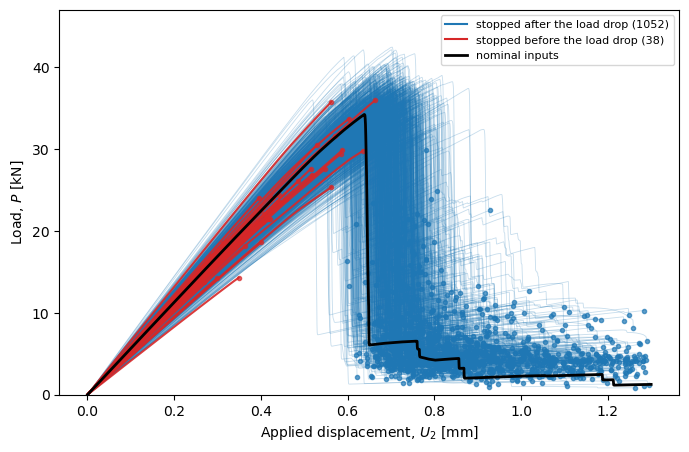

In [16]:
def drop_share(r):
    """Lowest load after the peak, as a share of the peak load [-] (1 if the job stopped at the peak)."""
    # The reaction force from the peak onwards, over the peak value.
    rf2, peak = r["rf2"], r["peak_index"]
    return min(rf2[peak:]) / rf2[peak]


# The unfinished jobs, in two groups: those whose load fell below 80% of the peak, and those that stopped before.
unfinished = [r for r in all_results if not r["completed"]]
groups = {"stopped after the load drop": ([r for r in unfinished if drop_displacement(r) is not None], "C0", 0.6, 0.25),
          "stopped before the load drop": ([r for r in unfinished if drop_displacement(r) is None], "C3", 1.5, 0.9)}
fig, ax = plt.subplots(figsize=(8.0, 5.0))
for label, (members, color, width, alpha) in groups.items():
    # Each job as a line (the rare group bolder), with a dot where it stopped [kN against mm].
    for r in members:
        ax.plot(r["u2"], np.array(r["rf2"]) / 1e3, color=color, lw=width, alpha=alpha)
        ax.plot(r["u2"][-1], r["rf2"][-1] / 1e3, "o", color=color, ms=3, alpha=0.7)
    # One legend entry per group, and a summary line: size, where the jobs stopped, lowest load after the peak.
    ax.plot([], [], color=color, label="%s (%d)" % (label, len(members)))
    print("%-29s %3d jobs, stopped at U2 = %.2f-%.2f mm, lowest load after the peak at most %.2f of the peak" % (
        label, len(members), min(r["u2"][-1] for r in members), max(r["u2"][-1] for r in members),
        max(drop_share(r) for r in members)))
# The nominal curve as the reference.
ax.plot(nominal["u2"], np.array(nominal["rf2"]) / 1e3, "k-", lw=2, label="nominal inputs")
# Labels and legend.
ax.set_xlabel("Applied displacement, $U_2$ [mm]")
ax.set_ylabel("Load, $P$ [kN]")
ax.set_ylim(0.0, 1.05 * max(r["f_peak_n"] for r in all_results) / 1e3)
ax.legend(loc="upper right", fontsize=8)
plt.show()

The 1,090 unfinished jobs fall into two clear groups. 1,052 stopped **after** the load had collapsed (blue), between
$U_2=0.60$ and 1.29 mm, when the plate was already broken; in every one of them the load fell to at most 0.74 of the
peak. Their first-ply failure and peak are recorded, so we keep them. 38 jobs stopped **before** the load drop (red),
on the rising branch, at $U_2=0.25$ to 0.66 mm and at loads from 13.8 to 36.0 kN. For them the "peak" is only the
last point, so we cannot see their peak load and they are rejected from the training. All 38 are training runs; the
five unfinished validation jobs all stopped after their drop.

No job lies between the two groups: the lowest load after the peak is either at most 0.74 of the peak or the peak
itself. The driver's threshold, a drop of at least 20%, falls in that empty gap, where its exact value does not
matter.

Are these 38 runs gathered in one part of the input space? If they were, dropping them would leave a hole in the design,
and the surrogate would know nothing about that part. The next cell standardises the inputs of the training runs (NB8's
$\xi_i=(x_i/\mu_i-1)/\mathrm{CoV}_i$, from each result's own inputs) and, with the helper `quarter_counts`, finds the input
on which the group lies furthest from the design's centre. It then counts how many runs of the lowest and of the highest quarter
of that input are in the group, next to the group's share over the whole design.

In [17]:
# The standardised inputs xi of every training run, from each result's own design row, and the 38 runs that stopped before the drop.
xi_train = (np.array([[r["design_row"][k] for k in INPUT_NAMES] for r in train_results]) / INPUT_MEANS - 1.0) / COV_INPUT
stopped = np.array([drop_displacement(r) is None for r in train_results])


def quarter_counts(xi, member):
    """Print where a group of runs lies on the input on which it is furthest from the design's centre.

    Parameters
    ----------
    xi : (n, d) array
        Standardised inputs of all the runs [-].
    member : (n,) bool array
        True for the runs of the group.
    """
    # The group's mean input in standard errors: the design's mean is 0, and the mean of n runs has standard error 1/sqrt(n).
    z = xi[member].mean(axis=0) * np.sqrt(member.sum())
    j = int(np.argmax(np.abs(z)))
    # The runs in the lowest and in the highest quarter of that input.
    low, high = xi[:, j] <= np.quantile(xi[:, j], 0.25), xi[:, j] >= np.quantile(xi[:, j], 0.75)
    print("%d runs of the group, %.2f%% of all %d; the input that separates them most is %s" % (
        member.sum(), 100 * member.mean(), len(member), INPUT_NAMES[j]))
    print("  lowest quarter of %s: %d of %d runs (%.2f%%); highest quarter: %d of %d runs (%.2f%%)" % (
        INPUT_NAMES[j], (member & low).sum(), low.sum(), 100 * member[low].mean(),
        (member & high).sum(), high.sum(), 100 * member[high].mean()))


quarter_counts(xi_train, stopped)

38 runs of the group, 0.39% of all 9792; the input that separates them most is Y_T
  lowest quarter of Y_T: 16 of 2448 runs (0.65%); highest quarter: 3 of 2448 runs (0.12%)


The stopped runs are not gathered in one corner of the input space. The input that separates them most is $Y_T$: 16 of the
2,448 runs in the lowest quarter of $Y_T$ stopped early (0.65%), against 3 of the 2,448 in the highest quarter (0.12%). So they are more
frequent where $Y_T$ is low, but even there 99 runs in 100 finished, and they turn up in every region. Dropping the 38 removes about
1 run in 250 (0.39%) from anywhere in the design, a little more from the low-$Y_T$ side, and leaves no hole in it.

### Step 4 &ndash; Runs with much viscous energy at the peak

NB6 chose the viscosity $\eta=10^{-4}$ so that the energy it dissipates (`ALLCD`) stays below 1% of the damage energy
(`ALLDMD`) at the peak. That check was made for the nominal inputs, and across the design the ratio varies. A high ratio
matters because `ALLCD` is dissipated on top of the damage energy that the fracture energies prescribe: while the viscosity
holds the damage back, the material can carry more load than its softening law allows. NB6 showed it on its coarsest mesh.
$\eta=10^{-2}$ (16% at the peak) gave a smooth curve and a peak 22% above the 34.0&ndash;34.1 kN plateau that smaller viscosities
reach, and $\eta=10^{-3}$ (3&ndash;6%) a rounded drop and a peak of 35.7 kN, 5% above it. So for a run at 1% or more the question
is whether its peak is artificially high and its failure artificially ductile.

The next cell defines `energy_ratio`, prints the spread of the ratio over every run with a load drop and how far above 1% the
flagged runs go, and draws their load curves over the nominal one (left) and a histogram of their ratio at the peak (right).

ALLCD/ALLDMD at the peak over 9854 runs: median 0.17%, 75th percentile 0.24%, max 13.11%; 184 runs at 1% or more
those 184 runs: quartiles 1.13%, 1.28%, 1.57%; 27 at 2% or more, 6 at 5% or more, 1 at 10% or more


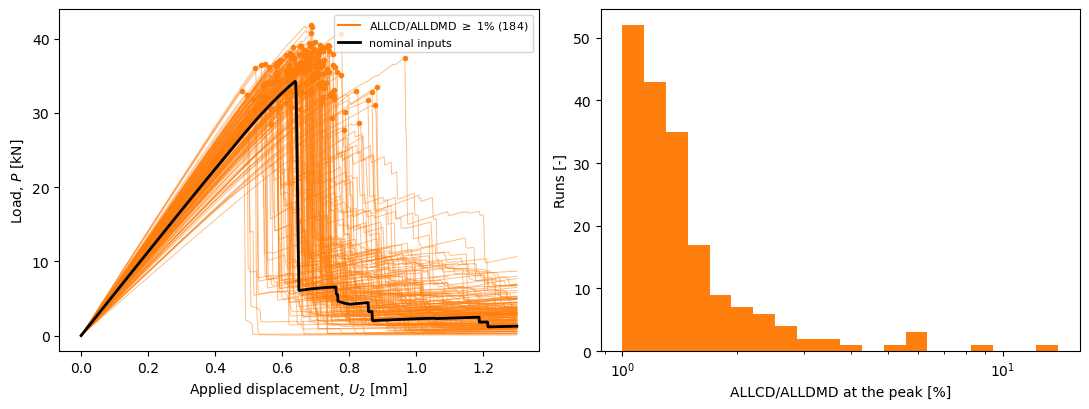

In [18]:
def energy_ratio(r):
    """ALLCD/ALLDMD at the peak: viscous over damage energy [-] (NaN if there is no damage energy yet)."""
    # Both energies at the frame of the peak load.
    allcd, alldmd = r["allcd"][r["peak_index"]], r["alldmd"][r["peak_index"]]
    return allcd / alldmd if alldmd > 0.0 else np.nan


# Every run with a load drop (Step 3), its energy ratio at the peak, and the runs at 1% or more.
dropped = [r for r in all_results if drop_displacement(r) is not None]
ratios = np.array([energy_ratio(r) for r in dropped])
high = ratios >= 0.01
# The spread of the ratio over all these runs, and how far above 1% the runs at 1% or more go.
print("ALLCD/ALLDMD at the peak over %d runs: median %.2f%%, 75th percentile %.2f%%, max %.2f%%; %d runs at 1%% or more"
      % (len(dropped), 100 * np.median(ratios), 100 * np.percentile(ratios, 75), 100 * ratios.max(), high.sum()))
print("those %d runs: quartiles %.2f%%, %.2f%%, %.2f%%; %d at 2%% or more, %d at 5%% or more, %d at 10%% or more"
      % (high.sum(), *(100 * np.percentile(ratios[high], [25, 50, 75])), (ratios >= 0.02).sum(), (ratios >= 0.05).sum(),
         (ratios >= 0.10).sum()))

# Two panels: the curves on the left, the histogram of the ratio on the right.
fig, (ax_c, ax_h) = plt.subplots(1, 2, figsize=(11.0, 4.2))
# Left: the curves of the runs at 1% or more, with their peaks, over the nominal curve [kN against mm].
for r in (r for r, h in zip(dropped, high) if h):
    ax_c.plot(r["u2"], np.array(r["rf2"]) / 1e3, color="C1", lw=0.7, alpha=0.5)
    ax_c.plot(r["u2_peak_mm"], r["f_peak_n"] / 1e3, "o", color="C1", ms=3)
# A legend entry for the orange curves, the nominal curve in black, labels and legend.
ax_c.plot([], [], color="C1", label="ALLCD/ALLDMD $\\geq$ 1%% (%d)" % high.sum())
ax_c.plot(nominal["u2"], np.array(nominal["rf2"]) / 1e3, "k-", lw=2, label="nominal inputs")
ax_c.set_xlabel("Applied displacement, $U_2$ [mm]")
ax_c.set_ylabel("Load, $P$ [kN]")
ax_c.legend(loc="upper right", fontsize=8)
# Right: the ratio at the peak of those runs on a logarithmic axis, since it runs from 1% to over 10%.
ax_h.hist(100 * ratios[high], bins=np.geomspace(1.0, 14.0, 21), color="C1")
ax_h.set(xscale="log", xlabel="ALLCD/ALLDMD at the peak [%]", ylabel="Runs [-]")
# Arrange the panels without overlaps.
fig.tight_layout()
plt.show()

Across the 9,854 runs with a load drop, the median ratio at the peak is 0.17% and three runs in four stay below 0.24%: for most
runs the viscosity dissipates a negligible energy, as NB6 intended. 184 runs reach 1% or more, but most only just: half of them are
below 1.28% and three in four below 1.57%. 27 reach 2%, 6 reach 5% and only one reaches 10% (13.1%), as the histogram shows.

On the left, the curves of these runs rise, peak and collapse like the nominal one: in essentially all of them the load still falls
almost vertically, nothing like the smooth, rounded curves that NB6's $\eta=10^{-2}$ and $10^{-3}$ gave. That is a good sign, but it
does not settle whether the peaks were raised. The nominal run itself drops vertically and still has a peak about 2% above the
plateau (NB6), so a brittle failure does not rule out a small bias.

Judging from the left panel alone is not enough, because the question is about the whole run, not only its collapse. NB6's
sign of a biased peak is a ratio that is already high *before* the peak and rises steadily towards it: with $\eta=10^{-2}$ it was
above 5% from 0.2 mm before the peak on, and with $\eta=10^{-3}$ already about 0.4% from 0.3 mm before it, far above the
nominal run's. So the next cell plots
`ALLCD/ALLDMD` against the displacement before the peak, $U_2-\delta_{ULT}$, up to the peak, for the runs at 1% or more, the
nominal run and NB6's $\eta=10^{-3}$ run (same mesh and increment cap, 0.01). It prints the ratio 0.1 mm before the peak for the
nominal run, the $\eta=10^{-3}$ run and the runs at 1% or more, and how many of those are above the $\eta=10^{-3}$ run.

ratio 0.1 mm before the peak: nominal 0.03%, NB6 eta = 1e-3 run 0.44%; the 184 runs at 1% or more: median 0.04%, 5 above the eta = 1e-3 run, 3 above 1%


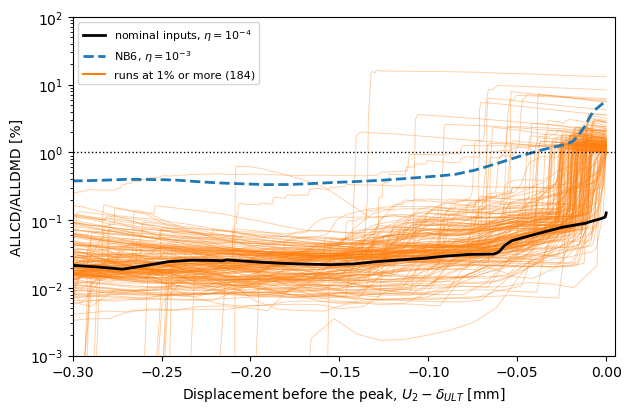

In [19]:
def ratio_history(r):
    """ALLCD/ALLDMD in every frame up to the peak [-] (0 where there is no damage energy yet)."""
    # The two energies up to the peak frame, and their ratio where the damage energy is positive.
    k = r["peak_index"] + 1
    allcd, alldmd = np.array(r["allcd"][:k]), np.array(r["alldmd"][:k])
    return np.divide(allcd, alldmd, out=np.zeros_like(allcd), where=alldmd > 0.0)


def ratio_before_peak(r, du=0.1):
    """ALLCD/ALLDMD at du [mm] before the peak's displacement, by linear interpolation [-]."""
    # The displacements up to the peak, and the ratio there, read at u2_peak - du.
    u = np.array(r["u2"][:r["peak_index"] + 1])
    return np.interp(r["u2_peak_mm"] - du, u, ratio_history(r))


# NB6's run with eta = 1e-3 on mesh M1 and increment cap 0.01: its result file.
with open(Path("../runs/nb06/grid_M1_v1e-3_c0p01.json")) as f:
    visc3 = json.load(f)
# The ratio 0.1 mm before the peak: the nominal run, NB6's eta = 1e-3 run, and the runs at 1% or more.
before = np.array([ratio_before_peak(r) for r, h in zip(dropped, high) if h])
ref_nominal, ref_visc3 = ratio_before_peak(nominal), ratio_before_peak(visc3)
print("ratio 0.1 mm before the peak: nominal %.2f%%, NB6 eta = 1e-3 run %.2f%%; the %d runs at 1%% or more: median %.2f%%, "
      "%d above the eta = 1e-3 run, %d above 1%%" % (100 * ref_nominal, 100 * ref_visc3, high.sum(), 100 * np.median(before),
                                                      (before > ref_visc3).sum(), (before > 0.01).sum()))

# The ratio against the displacement before the peak [%]: the runs at 1% or more, the nominal run, NB6's eta = 1e-3 run.
fig, ax = plt.subplots(figsize=(7.0, 4.4))
for r in (r for r, h in zip(dropped, high) if h):
    ax.plot(np.array(r["u2"][:r["peak_index"] + 1]) - r["u2_peak_mm"], 100 * ratio_history(r), color="C1", lw=0.6, alpha=0.4)
for r, style, label in ((nominal, "k-", "nominal inputs, $\\eta=10^{-4}$"), (visc3, "C0--", "NB6, $\\eta=10^{-3}$")):
    ax.plot(np.array(r["u2"][:r["peak_index"] + 1]) - r["u2_peak_mm"], 100 * ratio_history(r), style, lw=2, label=label)
# A legend entry for the orange curves, the 1% line, a logarithmic axis, labels.
ax.plot([], [], color="C1", label="runs at 1%% or more (%d)" % high.sum())
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set(yscale="log", xlim=(-0.3, 0.005), ylim=(1e-3, 1e2), xlabel="Displacement before the peak, $U_2-\\delta_{ULT}$ [mm]",
       ylabel="ALLCD/ALLDMD [%]")
ax.legend(loc="upper left", fontsize=8)
plt.show()

NB6's sign of a viscosity-raised peak is a ratio that is high well before the peak. Its $\eta=10^{-3}$ run (blue) stays near 0.4% from
0.3 mm before the peak on, and the nominal run (black) stays more than ten times lower, at 0.02&ndash;0.1%. Almost all of the 184 runs
follow the nominal trend: low, rising slowly, then steeply in the last few hundredths of a millimetre before the peak. At 0.1 mm
before the peak their median ratio is 0.04%, against 0.03% for the nominal run and 0.44% for the $\eta=10^{-3}$ run, and only 5 of
the 184 are above that run, 3 of them above 1%. A few runs show more viscous energy than the nominal trend from the start, or jump
to 10% or more well before the peak.

This alone cannot tell whether the peak of these runs was made artificially higher. A rigorous check would rerun them with a
smaller $\eta$ and see whether the peak changes much. More practically, NB10 (Part 3) fits the surrogate without these runs and
with them, and its Part 2 compares the distribution of $P_{ULT}$ with and without them.

Last, are the runs at 1% or more gathered in one part of the input space? The cell repeats Step 3's `quarter_counts` for
them.

In [20]:
# The training runs at 1% or more, as a mask over the design rows (a run with no load drop, or no damage energy, is not one of them).
flagged = np.array([drop_displacement(r) is not None and energy_ratio(r) >= 0.01 for r in train_results])
quarter_counts(xi_train, flagged)

184 runs of the group, 1.88% of all 9792; the input that separates them most is X_T
  lowest quarter of X_T: 13 of 2448 runs (0.53%); highest quarter: 95 of 2448 runs (3.88%)


The runs at 1% or more lean towards the high-$X_T$ side: 95 of the 2,448 runs in the highest quarter of $X_T$ are among them
(3.88%), against 13 in the lowest quarter (0.53%). Like the stopped runs they are not gathered in one corner: they turn up in every
region, and even in the highest quarter of $X_T$ 96 runs in 100 are below 1%. Leaving them out of a fit in NB10 therefore takes about
1 run in 26 from the high-$X_T$ side, fewer elsewhere, and leaves no hole in the design.

### Step 5 &ndash; The screening rule, and the element-size ceiling

The previous steps set the rule that the driver now applies (its `acceptance_reason`, imported at the top). A run is
**accepted** if

- first-ply failure was found;
- the load falls by at least 20% after the peak, so the peak is not just the last recorded point (whether or not the
  job reached $U_2=1.3$ mm).

The viscous energy is **not** a test: the runs with `ALLCD/ALLDMD` of 1% or more pass, flagged by their ratio. The
cell re-screens every result with this rule and counts the outcome.

In [21]:
# The rule's verdict for every run: '' if accepted, otherwise the reason.
reason_train = [acceptance_reason(r) for r in train_results]
reason_valid = [acceptance_reason(r) for r in valid_results]
# Accepted runs as boolean masks over the design rows.
ok_train = np.array([reason == "" for reason in reason_train])
ok_valid = np.array([reason == "" for reason in reason_valid])
for label, reasons in (("training", reason_train), ("validation", reason_valid)):
    # The count of each verdict, most frequent first.
    print("%s:" % label)
    for reason, count in Counter(reason or "accepted" for reason in reasons).most_common():
        print("  %4d  %s" % (count, reason))

training:
  9754  accepted
    38  no clear load drop after the peak
validation:
   100  accepted


With this rule, 9,754 of the 9,792 training runs (99.6%) and all 100 validation runs are accepted. The only runs lost
are the 38 jobs that stopped before their load drop. The 184 runs with more viscous energy are kept for now, and so
are the three runs whose peak the failed frame had hidden (Step 1). Whether the 184 change the surrogate is left to
NB10 (Part 3), which fits it without them, checks whether they sit above that fit, and then fits it with them.

One more property of each run matters. NB6 derived an element-size **ceiling** for the fracture-energy softening, $L_c<2E_2G_{mT}/Y_T^2$ for matrix
tension ([NB6](06_open_hole_tension.ipynb), element-size limit), and [NB7](07_element_size_ceiling.ipynb) showed
that a damaged element above it silently dissipates more than the prescribed fracture energy, which biases the run. Mesh M1 breaks it in 68% of its elements for the *nominal*
inputs. The ceiling depends on three of the uncertain inputs ($E_2$, $G_{mT}$, $Y_T$), so it moves from sample to
sample while the mesh stays fixed, and each result file records the share of elements above **that sample's own
ceiling**. The cell plots those shares for all 9,892 runs.

Share of M1 elements above the run's own L_c ceiling, over 9892 runs:
  nominal inputs 68%;  design: min 7%, median 68%, max 100%


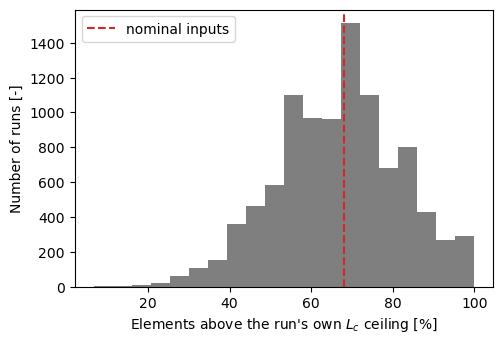

In [22]:
# Share of elements above each run's own L_c ceiling, for every run, and for the nominal inputs.
share_over = np.array([r["frac_elements_over_ceiling"] for r in all_results])
share_nominal = nominal["frac_elements_over_ceiling"]
# Report the nominal share and the range of the design.
print("Share of M1 elements above the run's own L_c ceiling, over %d runs:" % len(share_over))
print("  nominal inputs %.0f%%;  design: min %.0f%%, median %.0f%%, max %.0f%%" % (
    100 * share_nominal, 100 * share_over.min(), 100 * np.median(share_over), 100 * share_over.max()))
# Histogram of the shares, with the nominal value marked.
fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.hist(100 * share_over, bins=20, color="C7")
ax.axvline(100 * share_nominal, color="C3", ls="--", label="nominal inputs")
# Labels and legend.
ax.set_xlabel("Elements above the run's own $L_c$ ceiling [%]")
ax.set_ylabel("Number of runs [-]")
ax.legend()
plt.show()

For the nominal inputs 68% of M1's elements are above the ceiling, as NB6 found. Across the design the share runs from
7% to 100%, with a median of 68%: a typical sample breaks the ceiling in two thirds of the mesh, and some samples in
every element. By NB7, the damaged elements above the ceiling dissipate more energy than prescribed, by an amount
that changes from sample to sample. Whether this shows in the outputs is a question for NB10 and NB11.

## Conclusion

This notebook turned NB8's polynomial chaos expansion into an Abaqus campaign of 9,892 runs of the OHT plate, made
it affordable, ran it and checked every run before anything is fitted to it.

- **The budget** follows from the number of terms and the runs per coefficient. With 15 inputs, order 3 has 816
  terms and sets the size of the campaign. We grew it in three stages, $n_p=2$, 4 and 12 (1,632, 3,264 and 9,792
  training runs), plus 100 validation runs, because the order-3 error of the peak load had not settled. One nested
  random stream let every stage reuse every run already made.
- **Parallel computing** gains little within one job and much across jobs. Six cores speed one run up by only 1.26
  (Amdahl's $s=0.73$: in a model of 1,200 elements most of the work of an increment is not shared out). Identical
  single-core jobs side by side give a throughput gain close to $k$ up to 4, then 4.7 at 6 and only 5.3 at 11 on the
  6-core desktop: the physical cores, not the logical processors, set the throughput.
- **Running a campaign** for hours on shared licences calls for a template input file (no CAE licence per job), a
  licence check before each launch, and results saved run by run so that the campaign can be resumed. The real time
  depends on more than the machine: batch 1 matched its estimate, batches 2 and 3 took more than twice theirs,
  limited by the free licence tokens and a busier server, 32.6 h in all.
- **Screening** first removes the failed last frame that every job stopping early writes, which in three runs had
  been taken for the peak. It then keeps every run whose load fell by at least 20% after the peak. Only the 38 jobs that stopped before
  their drop are rejected, so 9,754 of the 9,792 training runs and all 100 validation runs can be used. The 184
  runs with ALLCD/ALLDMD of 1% or more are kept and flagged: they still fail abruptly and most follow the nominal
  run's energy ratio until just before the peak, but that cannot prove their peaks are unbiased, so NB10 tests it.

**What's next.** [NB10](10_pce_surrogate_open_hole_tension.ipynb) fits PCE surrogates of orders 1 to 3 of the two loads
to these runs, judges their error, and uses the best one for the mean, the standard deviation, the probability density
and the Sobol' indices of each load, set beside the raw runs and beside Thapa et al. (2021).